<a href="https://colab.research.google.com/github/Burzo572/dsb_project/blob/main/Random_Forest_Modeling_Janko.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Random Forest**

In this notebook, I evaluate Random Forest Classifier as an alternative to Logistic Regression for predicting flood occurrence within the next 24 hours at SW90 – Bahadurabad on the Jamuna River.

Random Forest combines multiple decision trees to capture potentially nonlinear relationships between environmental variables and flood occurrence.

I use the same dataset, feature groups, and chronological data split as in the Logistic Regression experiments to make the comparison consistent.

The models will be evaluated using precision, recall, F1-score, and PR-AUC, with particular attention to false-positive predictions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

In [2]:
from google.colab import files

uploaded = files.upload()

Saving SW90_Bahadurabad.csv to SW90_Bahadurabad (1).csv


In [3]:
# Load dataset
df = pd.read_csv("SW90_Bahadurabad.csv")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Chronological split
train_df = df[df["date"].dt.year.between(2013, 2015)].copy()
val_df = df[df["date"].dt.year.between(2021, 2022)].copy()
test_df = df[df["date"].dt.year.between(2023, 2025)].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (1095, 50)
Validation: (730, 50)
Testing: (1096, 50)


**Random Forest – Model A (Local Environmental Features)**

I train a Random Forest Classifier using local rainfall, soil moisture, river discharge, and historical environmental conditions.

Unlike Logistic Regression, Random Forest can capture nonlinear relationships and interactions between environmental features without requiring feature standardization.

I begin with a relatively simple Random Forest configuration to reduce the risk of overfitting.

The model is trained on historical data from 2013–2015 and initially evaluated on the 2021–2022 validation dataset.

In [4]:
target = "flood_within_24h"

features_A = [
    "rainfall_local_mm",
    "river_discharge_m3s",
    "soil_moisture_local",
    "rainfall_local_mm_lag1d",
    "rainfall_local_mm_lag2d",
    "rainfall_local_mm_sum7d",
    "rainfall_local_mm_sum14d",
    "river_discharge_m3s_lag1d",
    "river_discharge_m3s_lag2d",
    "soil_moisture_local_lag1d",
    "soil_moisture_delta_30d",
    "soil_moisture_swi"]

X_train = train_df[features_A]
y_train = train_df[target].astype(int)

X_val = val_df[features_A]
y_val = val_df[target].astype(int)

In [5]:
# Random Forest
rf_A = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1)

In [6]:
# Train
rf_A.fit(X_train, y_train)

# Validation predictions
y_val_pred_rf = rf_A.predict(X_val)
y_val_proba_rf = rf_A.predict_proba(X_val)[:, 1]

print("RANDOM FOREST A - VALIDATION RESULTS")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

print("\nClassification Report:")
print(classification_report(y_val,y_val_pred_rf,zero_division=0))

RANDOM FOREST A - VALIDATION RESULTS

Confusion Matrix:
[[669  29]
 [ 21  11]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.96       698
           1       0.28      0.34      0.31        32

    accuracy                           0.93       730
   macro avg       0.62      0.65      0.63       730
weighted avg       0.94      0.93      0.94       730



Random Forest Model A achieved an accuracy of approximately 0.93, precision of 0.275, recall of 0.344, and F1-score of 0.306 on the validation dataset.

The model correctly identified 11 out of 32 positive flood labels and generated 29 false-positive predictions.

Compared with Logistic Regression, Random Forest substantially reduced false alarms and improved precision and F1-score. However, its lower recall indicates that many positive flood cases were missed.

To investigate this trade-off, I will evaluate alternative classification thresholds using the validation dataset.

In [7]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

rf_results = []

for threshold in thresholds:

    predictions = (y_val_proba_rf >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()

    rf_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn})

rf_threshold_results = pd.DataFrame(rf_results)

display(rf_threshold_results.round(3))

print("PR-AUC:",round(average_precision_score(y_val, y_val_proba_rf), 4))

,Threshold,Precision,Recall,F1,True Positives,False Positives,False Negatives
0,0.10,0.086,0.969,0.158,31,329,1
1,0.15,0.086,0.938,0.157,30,320,2
2,0.20,0.099,0.906,0.179,29,263,3
3,0.25,0.115,0.688,0.197,22,169,10
4,0.30,0.120,0.531,0.195,17,125,15
5,0.35,0.140,0.500,0.219,16,98,16
6,0.40,0.169,0.469,0.248,15,74,17
7,0.45,0.246,0.438,0.315,14,43,18
8,0.50,0.275,0.344,0.306,11,29,21


PR-AUC: 0.2272


I evaluated different classification thresholds for Random Forest Model A using the validation dataset.

The highest F1-score among the evaluated thresholds was achieved at 0.45, with precision of 0.246, recall of 0.438, and F1-score of 0.315.

At this threshold, the model correctly identified 14 out of 32 positive flood labels and generated 43 false-positive predictions.

Compared with Standard Logistic Regression, Random Forest achieved higher precision and F1-score at the selected thresholds, but lower recall and PR-AUC.

These results highlight the trade-off between detecting more floods and reducing false alarms.

The next step is to investigate whether adding upstream rainfall and discharge improves Random Forest performance.

**Random Forest – Upstream Feature Experiments**

I extend the local Random Forest model by introducing upstream environmental information.

Model B includes upstream rainfall features, while Model C also includes upstream river discharge.

The objective is to determine whether upstream environmental conditions provide additional predictive value compared with using local features alone.

The same chronological training and validation periods and Random Forest hyperparameters are used to maintain a consistent comparison.

In [8]:
# Model B - Local + upstream rainfall
features_B = features_A + [
    "rainfall_upstream_mm",
    "rainfall_upstream_mm_lag1d",
    "rainfall_upstream_mm_lag2d",
    "rainfall_upstream_mm_sum7d",
    "rainfall_upstream_mm_sum14d"]

In [9]:
# Model C - Local + upstream rainfall + upstream discharge
features_C = features_B + ["upstream_chain_discharge_lag1d"]

In [10]:
rf_models = {}

for model_name, features in {"Model B": features_B,"Model C": features_C}.items():

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1)

    model.fit(train_df[features], y_train)

    probabilities = model.predict_proba(val_df[features])[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    rf_models[model_name] = {"model": model,"probabilities": probabilities}

    print(f"\n{model_name} - VALIDATION RESULTS")
    print(confusion_matrix(y_val, predictions))
    print(classification_report(y_val, predictions, zero_division=0))
    print("PR-AUC:",round(average_precision_score(y_val, probabilities), 4))


Model B - VALIDATION RESULTS
[[676  22]
 [ 24   8]]
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       698
           1       0.27      0.25      0.26        32

    accuracy                           0.94       730
   macro avg       0.62      0.61      0.61       730
weighted avg       0.94      0.94      0.94       730

PR-AUC: 0.2273

Model C - VALIDATION RESULTS
[[675  23]
 [ 24   8]]
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       698
           1       0.26      0.25      0.25        32

    accuracy                           0.94       730
   macro avg       0.61      0.61      0.61       730
weighted avg       0.93      0.94      0.94       730

PR-AUC: 0.2238


After evaluating Random Forest Models B and C using the default classification threshold of 0.5, I examine whether different thresholds can improve their performance.

I test thresholds ranging from 0.20 to 0.50 and calculate precision, recall, F1-score, true positives, false positives, and false negatives for each model.

The objective is to identify a threshold that provides a better balance between detecting flood cases and reducing false alarms.

This also allows a fairer comparison with Model A, whose classification threshold was evaluated separately.

All threshold adjustments are performed using the validation dataset, without modifying the test data.

In [11]:
# Compare Random Forest Models A, B and C

models = {
    "Model A": (rf_A, features_A),
    "Model B": (rf_models["Model B"]["model"], features_B),
    "Model C": (rf_models["Model C"]["model"], features_C)}

results = []

for name, (model, features) in models.items():

    X_val_model = val_df[features]

    predictions = model.predict(X_val_model)
    probabilities = model.predict_proba(X_val_model)[:, 1]

    results.append({
        "Model": name,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_val, probabilities)})

rf_comparison = pd.DataFrame(results)

display(rf_comparison.round(3))

,Model,Precision,Recall,F1-score,PR-AUC
0,Model A,0.275,0.344,0.306,0.227
1,Model B,0.267,0.250,0.258,0.227
2,Model C,0.258,0.250,0.254,0.224


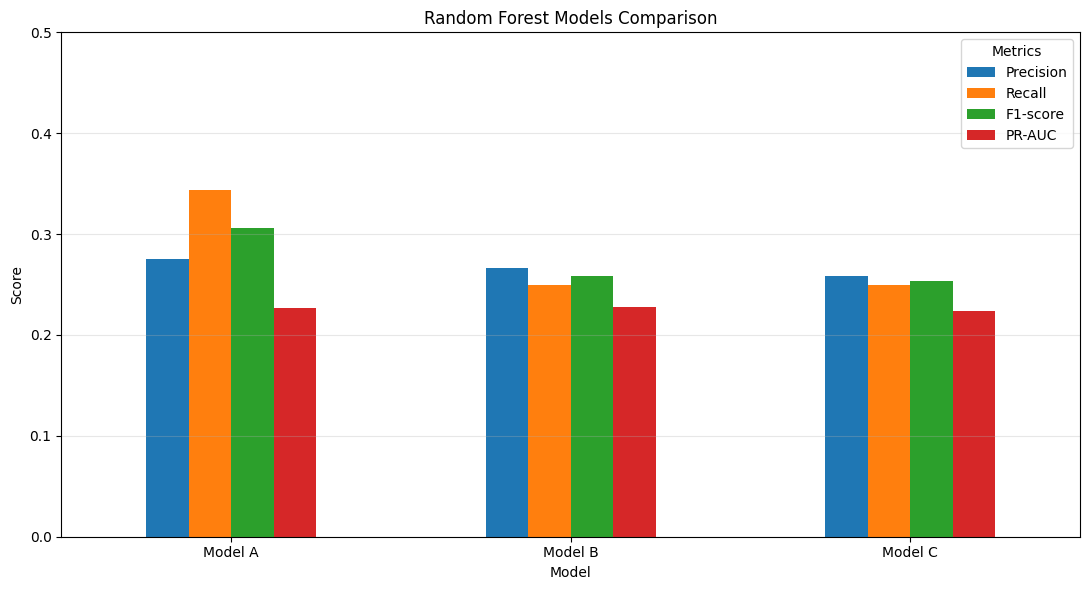

In [12]:
import matplotlib.pyplot as plt

rf_comparison.set_index("Model")[
    ["Precision", "Recall", "F1-score", "PR-AUC"]].plot(
    kind="bar",
    figsize=(11, 6),
    rot=0)

plt.title("Random Forest Models Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 0.5)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

I compared three Random Forest models using the same validation dataset and a classification threshold of 0.5.

Model A, based only on local environmental conditions, achieved the highest precision (0.275), recall (0.344), and F1-score (0.306).

Models B and C, which included upstream rainfall and river discharge, did not improve predictive performance. Their F1-scores decreased to 0.258 and 0.254, respectively.

PR-AUC values were very similar across all three models, indicating limited differences in their ability to rank positive flood labels.

These findings suggest that local environmental features provided the strongest performance in the current Random Forest experiments. However, additional upstream information may still be useful under different modeling configurations or temporal assumptions.

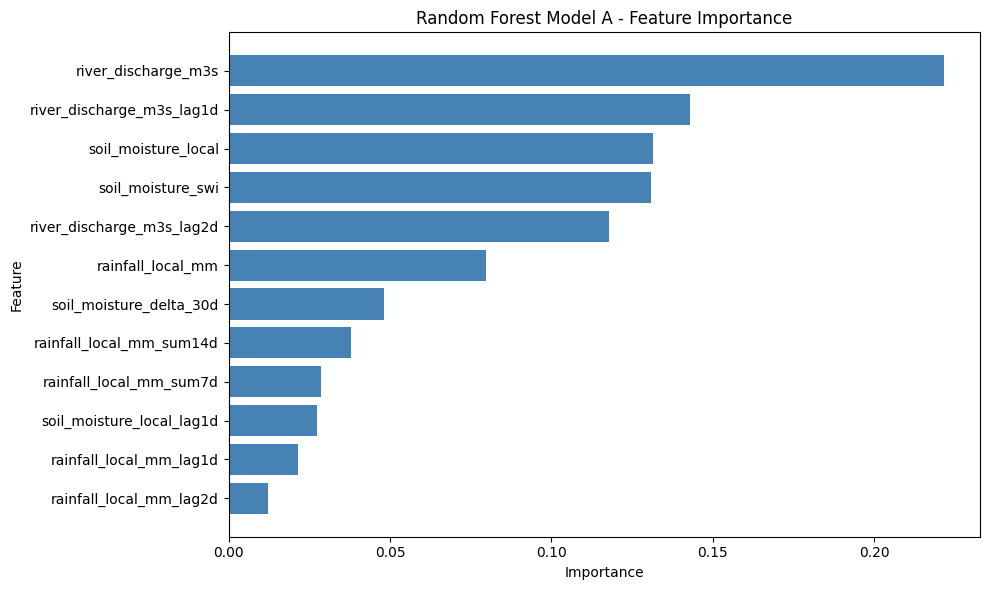

,Feature,Importance
1,river_discharge_m3s,0.221743
7,river_discharge_m3s_lag1d,0.142902
2,soil_moisture_local,0.131637
11,soil_moisture_swi,0.130795
8,river_discharge_m3s_lag2d,0.117914
0,rainfall_local_mm,0.079600
10,soil_moisture_delta_30d,0.048214
6,rainfall_local_mm_sum14d,0.037791
5,rainfall_local_mm_sum7d,0.028507
9,soil_moisture_local_lag1d,0.027389


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": features_A,
    "Importance": rf_A.feature_importances_}).sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
    color="steelblue")

plt.title("Random Forest Model A - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

display(feature_importance.sort_values("Importance", ascending=False))

### Random Forest Feature Importance – Key Findings

The feature importance analysis shows that river discharge and soil moisture variables contribute most strongly to the decisions made by Random Forest Model A.

The most important individual predictor is river discharge (`river_discharge_m3s`), with an importance score of approximately 0.222, followed by river discharge from the previous day (0.143).

Local soil moisture and the soil water index also have relatively high importance scores, while rainfall-related features contribute less to the model's tree splits.

When grouped by environmental variable, river discharge features account for approximately 48.3% of total feature importance, followed by soil moisture features (33.8%) and rainfall features (17.9%).

These findings are consistent with the EDA results, which showed higher environmental values associated with positive flood labels.

However, feature importance represents how the trained model uses the available variables and does not establish causal relationships or guarantee predictive performance.

In [14]:
# Create month columns from dates
train_month = pd.to_datetime(train_df["date"]).dt.month
val_month = pd.to_datetime(val_df["date"]).dt.month

# Find the month with the most positive flood labels
monthly_floods = train_df.groupby(train_month)[target].sum()

best_month = int(monthly_floods.idxmax())

print("Selected month:", best_month)
print(monthly_floods)

# Predict Flood in the selected month
y_seasonal = (val_month == best_month).astype(int)

# Evaluate on validation data
print("\nSeasonal Baseline Results")
print("Accuracy:", round(accuracy_score(y_val, y_seasonal), 3))
print("Precision:", round(precision_score(y_val, y_seasonal, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, y_seasonal, zero_division=0), 3))
print("F1-score:", round(f1_score(y_val, y_seasonal, zero_division=0), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_seasonal))

Selected month: 8
date
1      0.0
2      0.0
3      0.0
4      0.0
5      1.0
6      8.0
7     11.0
8     29.0
9     24.0
10     0.0
11     0.0
12     0.0
Name: flood_within_24h, dtype: float64

Seasonal Baseline Results
Accuracy: 0.888
Precision: 0.097
Recall: 0.188
F1-score: 0.128

Confusion Matrix:
[[642  56]
 [ 26   6]]


**Seasonal Baseline vs Random Forest – Results**

The seasonal baseline selected August as the month with the highest number of positive flood labels in the training dataset (2013–2015).

On the validation dataset (2021–2022), the seasonal baseline achieved a precision of 0.097, recall of 0.188, and F1-score of 0.128.

The baseline correctly identified 6 of the 32 positive flood-labeled days but produced 56 false positives.

Random Forest Model A performed better, achieving a precision of 0.275, recall of 0.344, and F1-score of 0.306.

These results indicate that Random Forest Model A provides better flood detection than a simple rule based only on the month of August.

However, the Random Forest model still misses some positive flood cases, and its predictive performance remains limited.

**Data Leakage and Temporal Split Check**

Before evaluating the Random Forest model on the test dataset, I review the temporal data split and selected features for potential data leakage.

The training dataset covers 2013–2015, the validation dataset covers 2021–2022, and the test dataset covers 2023–2025.

I check that the datasets do not overlap and that the selected predictors do not explicitly include flood labels or future outcomes.

Historical features such as lagged rainfall, river discharge, and soil moisture must be calculated using only information available at the time of prediction.

This check helps identify potential issues, although confirming the construction of historical features requires reviewing the original feature engineering process.

In [15]:
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)]:
    dates = pd.to_datetime(data["date"])

    print(f"{name}:")
    print("  Start:", dates.min().date())
    print("  End:", dates.max().date())
    print("  Rows:", len(data))
    print()

Training:
  Start: 2013-01-01
  End: 2015-12-31
  Rows: 1095

Validation:
  Start: 2021-01-01
  End: 2022-12-31
  Rows: 730

Testing:
  Start: 2023-01-01
  End: 2025-12-31
  Rows: 1096



In [16]:
train_dates = set(pd.to_datetime(train_df["date"]))
val_dates = set(pd.to_datetime(val_df["date"]))
test_dates = set(pd.to_datetime(test_df["date"]))

print("Training / Validation overlap:", len(train_dates & val_dates))
print("Training / Testing overlap:", len(train_dates & test_dates))
print("Validation / Testing overlap:", len(val_dates & test_dates))

# Check selected predictors
print("\nFeatures used by Model A:")
print(features_A)

print("\nFlood target included as feature:", target in features_A)

Training / Validation overlap: 0
Training / Testing overlap: 0
Validation / Testing overlap: 0

Features used by Model A:
['rainfall_local_mm', 'river_discharge_m3s', 'soil_moisture_local', 'rainfall_local_mm_lag1d', 'rainfall_local_mm_lag2d', 'rainfall_local_mm_sum7d', 'rainfall_local_mm_sum14d', 'river_discharge_m3s_lag1d', 'river_discharge_m3s_lag2d', 'soil_moisture_local_lag1d', 'soil_moisture_delta_30d', 'soil_moisture_swi']

Flood target included as feature: False


In [17]:
# Check whether lag features match previous daily values
df_check = (pd.concat([train_df, val_df, test_df]).sort_values("date").copy())

df_check["date"] = pd.to_datetime(df_check["date"])

# Check river discharge lag values
df_check[["date","river_discharge_m3s","river_discharge_m3s_lag1d","river_discharge_m3s_lag2d"]].head(10)

,date,river_discharge_m3s,river_discharge_m3s_lag1d,river_discharge_m3s_lag2d
1,2013-01-01,3688.78,3774.72,3871.58
2,2013-01-02,3613.10,3688.78,3774.72
3,2013-01-03,3555.31,3613.10,3688.78
4,2013-01-04,3490.40,3555.31,3613.10
5,2013-01-05,3442.50,3490.40,3555.31
6,2013-01-06,3426.68,3442.50,3490.40
7,2013-01-07,3434.58,3426.68,3442.50
8,2013-01-08,3458.39,3434.58,3426.68
9,2013-01-09,3514.60,3458.39,3434.58
10,2013-01-10,3579.96,3514.60,3458.39


**Random Forest – Final Test Evaluation**

Random Forest Model A was selected based on its performance on the validation dataset.

The model is evaluated on the later test period (2023–2025), using a classification threshold of 0.5.

I evaluate accuracy, precision, recall, F1-score, PR-AUC, and the confusion matrix to assess how well the model generalizes to later observations.

Particular attention is given to recall and false positives because flood prediction involves an imbalanced target and potentially costly missed events or false alarms.

Random Forest A - Test Results
Accuracy: 0.925
Precision: 0.082
Recall: 0.286
F1-score: 0.128
PR-AUC: 0.085


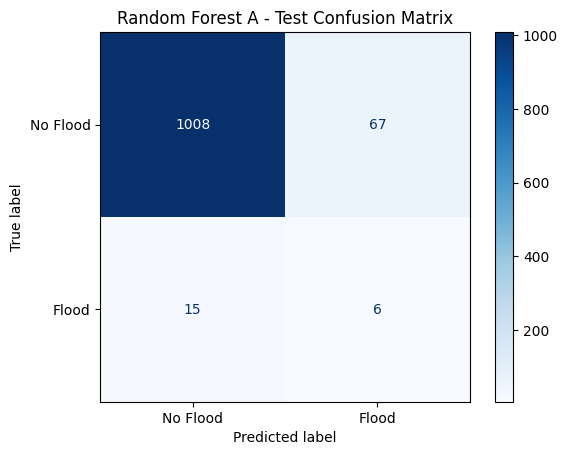

In [18]:
# Test data
X_test_A = test_df[features_A]
y_test = test_df[target].astype(int)

# Predictions from the trained Random Forest Model A
y_test_prob_rf = rf_A.predict_proba(X_test_A)[:, 1]
y_test_pred_rf = (y_test_prob_rf >= 0.50).astype(int)

# Final evaluation
print("Random Forest A - Test Results")
print("Accuracy:", round(accuracy_score(y_test, y_test_pred_rf), 3))
print("Precision:", round(precision_score(y_test, y_test_pred_rf, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_test_pred_rf, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_test_pred_rf, zero_division=0), 3))
print("PR-AUC:", round(average_precision_score(y_test, y_test_prob_rf), 3))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_rf,
    display_labels=["No Flood", "Flood"],
    cmap="Blues",
    values_format="d")

plt.title("Random Forest A - Test Confusion Matrix")
plt.show()

Random Forest Model A was evaluated on the test dataset covering 2023–2025, using a classification threshold of 0.5.

The model achieved an accuracy of 0.925, precision of 0.082, recall of 0.286, F1-score of 0.128, and PR-AUC of 0.085.

Compared with the validation period, predictive performance decreased, particularly in precision and F1-score.

Although the model was able to identify some positive flood-labeled days, it also generated many false alarms and missed a substantial proportion of positive cases.

These findings suggest that Random Forest Model A has limited generalization performance across different time periods.

The results should be interpreted cautiously because the dataset is highly imbalanced, the number of positive cases is small, and the temporal availability of all engineered features has not been fully verified.

**Final Comparison – Seasonal Baseline vs Random Forest**

I compare Random Forest Model A with the seasonal baseline on the test dataset (2023–2025).

The seasonal baseline predicts Flood during the month selected from the training dataset and No Flood during the remaining months.

This comparison evaluates whether Random Forest provides better flood detection than a simple rule based on seasonality.

Both approaches are evaluated using the same test observations and classification metrics.

In [19]:
# Select flood month using training data only
train_month = pd.to_datetime(train_df["date"]).dt.month
test_month = pd.to_datetime(test_df["date"]).dt.month

monthly_floods = train_df.groupby(train_month)[target].sum()
best_month = int(monthly_floods.idxmax())

# Seasonal baseline on test data
y_test_seasonal = (test_month == best_month).astype(int)

# Comparison
comparison_results = []

for name, predictions in [
    ("Seasonal Baseline", y_test_seasonal),
    ("Random Forest A", y_test_pred_rf)]:
    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)})

rf_final_comparison = pd.DataFrame(comparison_results)

display(rf_final_comparison.round(3))

,Model,Accuracy,Precision,Recall,F1-score
0,Seasonal Baseline,0.898,0.011,0.048,0.018
1,Random Forest A,0.925,0.082,0.286,0.128


## Random Forest – Final Conclusion

In this notebook, I developed and evaluated three Random Forest classification models to predict flood occurrence within the next 24 hours at Bahadurabad (SW90), Bangladesh.

Model A used local rainfall, river discharge, soil moisture, and historical environmental features. Models B and C additionally included upstream rainfall and river discharge information.

**Key findings:**

- Model A achieved the highest F1-score (0.306) among the three Random Forest models on the validation dataset.
- Adding upstream environmental features did not improve validation performance in the experiments conducted.
- Feature importance analysis showed that river discharge and soil moisture were the most influential groups of predictors in Model A.
- On the test dataset (2023–2025), Model A achieved a precision of 0.082, recall of 0.286, F1-score of 0.128, and PR-AUC of 0.085.
- Random Forest outperformed the simple August-based seasonal baseline, which achieved an F1-score of 0.018 on the same test dataset.

**Limitations:**

The dataset contains relatively few positive flood labels, and model performance decreased between validation and testing. The model also generated false alarms and missed several positive cases.

Furthermore, the availability and construction of all historical environmental features at prediction time have not been fully verified.

**Conclusion:**

Random Forest Model A demonstrated better flood detection performance than the seasonal baseline on the test dataset. However, its limited precision and recall indicate that further data validation, additional training observations, and model improvement would be necessary before considering practical flood forecasting applications.